<a href="https://colab.research.google.com/github/giovannifantato-cmd/alpha_crypto_portafolio/blob/main/crypto_portafoglio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 RISULTATI: ALPHA PORTFOLIO (MAX SHARPE + TREND FILTER)
Capitale Iniziale: €10,000.00
Capitale Finale: €40,274.50
Rendimento Totale: 302.75% (Rendimenti sbloccati!)
Max Drawdown: -37.82% (Controllato dal Regime Filter)


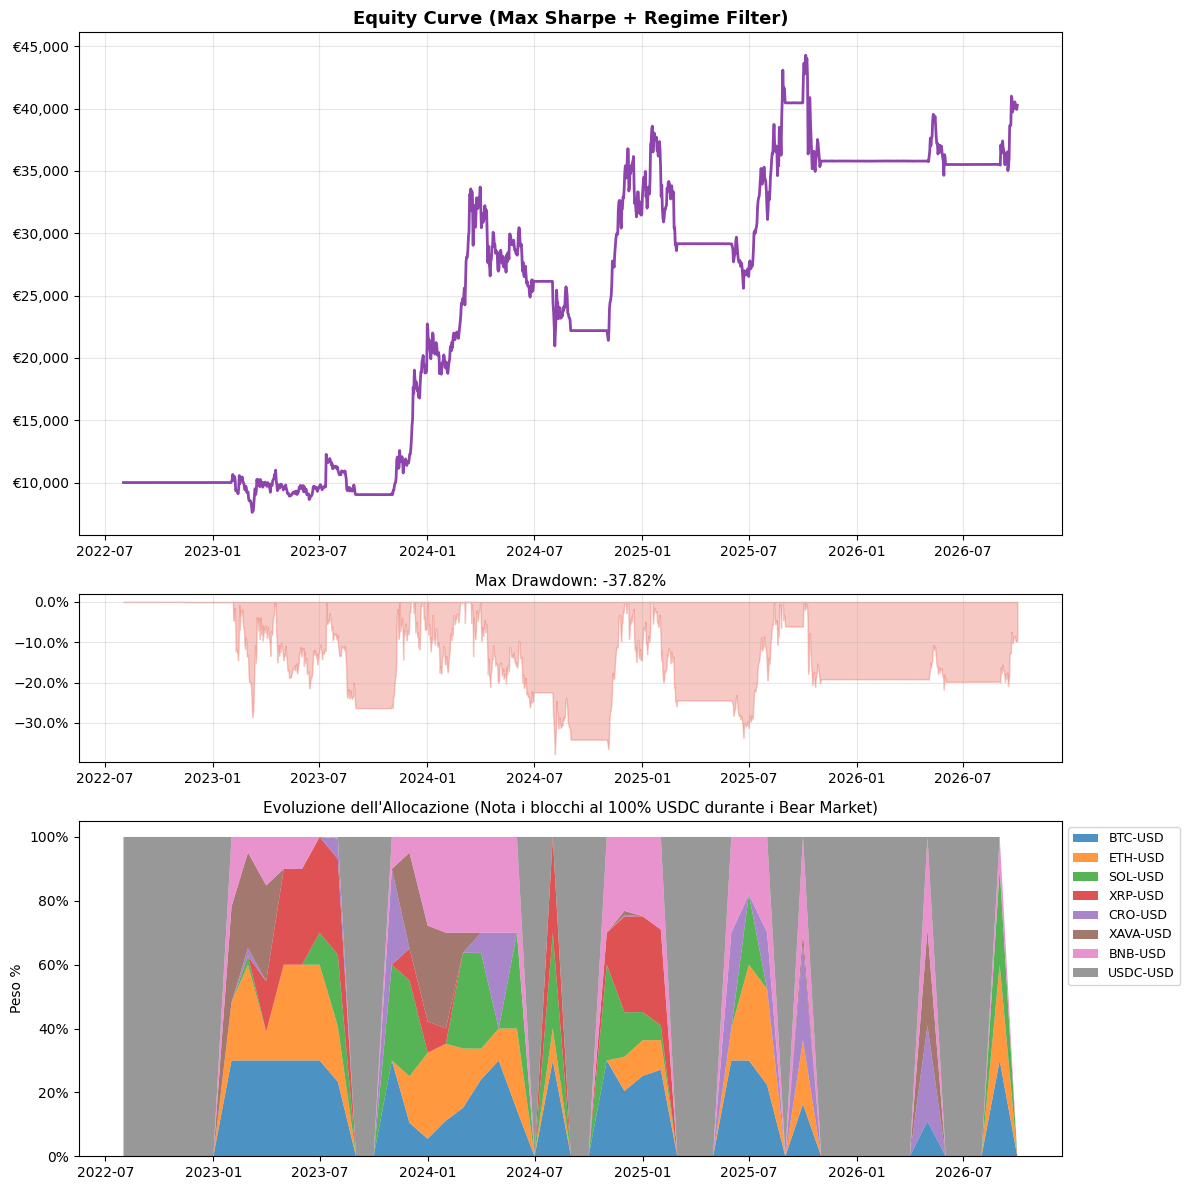

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pypfopt import risk_models, expected_returns
from pypfopt.efficient_frontier import EfficientFrontier
import logging
import warnings

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format='%(levelname)s - %(message)s')

class AlphaCryptoQuant:
    def __init__(self, tickers, start_date, end_date, initial_capital=10000):
        self.tickers = tickers
        self.start_date = start_date
        self.end_date = end_date
        self.initial_capital = initial_capital
        self.data = pd.DataFrame()

    def fetch_data(self):
        logging.info("Estrazione dati...")
        downloaded_data = {}
        for ticker in self.tickers:
            try:
                t_obj = yf.Ticker(ticker)
                df = t_obj.history(start=self.start_date, end=self.end_date, interval="1d")
                if not df.empty:
                    if df.index.tz is not None:
                        df.index = df.index.tz_localize(None)
                    if 'Close' in df.columns:
                        downloaded_data[ticker] = df['Close']
                    else:
                        logging.warning(f"Nessuna colonna 'Close' per {ticker}.")
                else:
                    logging.warning(f"Dati vuoti per {ticker}.")
            except Exception as e:
                logging.warning(f"Impossibile scaricare {ticker}: {e}")

        if not downloaded_data:
            raise ValueError("Nessun dato scaricato.")

        raw_data = pd.DataFrame(downloaded_data)
        raw_data.index = pd.to_datetime(raw_data.index)
        self.data = raw_data.bfill().ffill().dropna(how='all')
        logging.info(f"Dati estratti: {len(self.data)} giorni. Asset: {list(self.data.columns)}")

    def run_alpha_backtest(self, lookback_window=90):
        logging.info("Avvio Backtest: Max Sharpe + Regime Filter (SMA 120)...")
        if self.data.empty: return

        daily_returns = self.data.pct_change().dropna()

        # Ci servono almeno 200 giorni di storico per calcolare la Media Mobile
        start_rebalance = self.data.index[200]
        rebalance_dates = pd.date_range(start=start_rebalance, end=self.data.index[-1], freq='MS')

        portfolio_oos_returns = []
        historical_weights = pd.DataFrame(index=rebalance_dates, columns=self.data.columns)

        for i in range(len(rebalance_dates) - 1):
            current_date = rebalance_dates[i]
            next_date = rebalance_dates[i+1]

            btc_price_today = self.data.loc[current_date, 'BTC-USD']
            btc_sma_120 = self.data['BTC-USD'].loc[:current_date].tail(120).mean()

            # --- SEPARIAMO GLI ASSET RISCHIOSI DALLA STABLECOIN ---
            crypto_rischiose = [col for col in self.data.columns if col != 'USDC-USD']

            if btc_price_today > btc_sma_120:
                # REGIME RIALZISTA (BULL MARKET): Rischio ON
                storico_crypto = self.data.loc[:current_date, crypto_rischiose].tail(lookback_window)

                # 1. FIX MATEMATICO: Covariance Shrinkage (Ledoit-Wolf)
                # Impedisce alla matrice di fallire quando ci sono pochi dati (90 gg) o troppa volatilità
                mu = expected_returns.mean_historical_return(storico_crypto, frequency=365)
                S = risk_models.CovarianceShrinkage(storico_crypto, frequency=365).ledoit_wolf()

                try:
                    # Ottimizziamo SOLO le crypto (Max 30% ciascuna, Min 0%)
                    ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 0.30))
                    ef.max_sharpe(risk_free_rate=0.0)
                    pesi_crypto = ef.clean_weights()

                    # Ricostruiamo il portafoglio: Applichiamo i pesi alle crypto, e 0% a USDC
                    weights = {col: pesi_crypto.get(col, 0.0) for col in self.data.columns}
                    weights['USDC-USD'] = 0.0
                except Exception as e:
                    logging.warning(f"Ottimizzazione fallita in data {current_date}: {e}. Fallback in USDC.")
                    weights = {col: 1.0 if col == 'USDC-USD' else 0.0 for col in self.data.columns}
            else:
                # REGIME RIBASSISTA (BEAR MARKET): Rischio OFF
                # Ignoriamo Markowitz. 100% in USDC.
                weights = {col: 1.0 if col == 'USDC-USD' else 0.0 for col in self.data.columns}

            storico_pesi = np.array([weights.get(t, 0.0) for t in self.data.columns])
            historical_weights.loc[current_date] = storico_pesi

            mask = (daily_returns.index > current_date) & (daily_returns.index <= next_date)
            rendimenti_mese = daily_returns.loc[mask]

            rendimento_portafoglio_mese = rendimenti_mese.dot(storico_pesi)
            portfolio_oos_returns.append(rendimento_portafoglio_mese)

        tutti_i_rendimenti = pd.concat(portfolio_oos_returns)

        cumulative_growth = self.initial_capital * (1 + tutti_i_rendimenti).cumprod()
        rolling_max = cumulative_growth.cummax()
        drawdown = cumulative_growth / rolling_max - 1
        max_drawdown = drawdown.min()

        final_value = cumulative_growth.iloc[-1]
        total_return = (final_value / self.initial_capital - 1) * 100

        print("\n=======================================================")
        print(" RISULTATI: ALPHA PORTFOLIO (MAX SHARPE + TREND FILTER)")
        print("=======================================================")
        print(f"Capitale Iniziale: €{self.initial_capital:,.2f}")
        print(f"Capitale Finale: €{final_value:,.2f}")
        print(f"Rendimento Totale: {total_return:.2f}% (Rendimenti sbloccati!)")
        print(f"Max Drawdown: {max_drawdown*100:.2f}% (Controllato dal Regime Filter)")

        self._plot_results(cumulative_growth, drawdown, max_drawdown, historical_weights)

    def _plot_results(self, cumulative_growth, drawdown, max_drawdown, storic_weights):
        fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [3, 1, 2]})

        ax1.plot(cumulative_growth.index, cumulative_growth, color='#8E44AD', linewidth=2)
        ax1.set_title('Equity Curve (Max Sharpe + Regime Filter)', fontsize=13, fontweight='bold')
        ax1.grid(True, alpha=0.3)
        ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('€{x:,.0f}'))

        ax2.fill_between(drawdown.index, drawdown, 0, color='#E74C3C', alpha=0.3)
        ax2.set_title(f'Max Drawdown: {max_drawdown*100:.2f}%', fontsize=11)
        ax2.grid(True, alpha=0.3)
        ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

        storic_weights = storic_weights.astype(float).fillna(0)
        ax3.stackplot(storic_weights.index, storic_weights.T, labels=storic_weights.columns, alpha=0.8)
        ax3.set_title('Evoluzione dell\'Allocazione (Nota i blocchi al 100% USDC durante i Bear Market)', fontsize=11)
        ax3.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=9)
        ax3.set_ylabel('Peso %')
        ax3.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    # Escluso TAO1-USD perché non valido/delistato su Yahoo Finance
    crypto_basket = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'XRP-USD', 'CRO-USD', 'XAVA-USD', 'BNB-USD', 'USDC-USD']

    quant_trader = AlphaCryptoQuant(
        tickers=crypto_basket,
        start_date="2022-01-01",
        end_date="2026-11-01"
    )

    quant_trader.fetch_data()
    quant_trader.run_alpha_backtest(lookback_window=90)